# Coming home to charge: how a delivery drone lands on its charging port by itself

I am building Mote, a small quiet drone that brings you one coffee. After a few deliveries the battery runs low and the drone has to fly back to its port and charge, with nobody around to help

The charging contacts on a port are small, so the drone has to land within a few centimeters. GPS in a city is off by meters. So if the drone can't land precisely by itself, it can't charge by itself, and then it is not really autonomous

In this notebook I look at:

1. Act 1: how much battery a delivery takes and when the drone has to go home
2. Act 2: landing on the port using only GPS
3. Act 3: Kalman filter, combining GPS, IMU and a camera that sees a marker on the port
4. Act 4: what wind does to the last meters of landing
5. Act 5: how big the port has to be

Only numpy and matplotlib, no real drone needed

## Step 1: Setup

Numbers I use are my targets for Mote, not measured yet:

- drone 1.05 kg empty, 1.5 kg with a coffee
- 4 propellers 7 inch (17.8 cm)
- battery 4S 5000 mAh = 74 Wh, I only use 80% of it so it lives longer
- ring guards around the propellers, so the drag area is a bit bigger than a normal drone

For power I use momentum theory. A rotor that pushes air down with speed $v_i$ needs power $P = T v_i$. When hovering

$$v_h = \sqrt{\frac{T}{2\rho A}}$$

where $A$ is the area of all the propellers. When flying forward the rotor gets new air all the time, so induced speed goes down:

$$v_i^2 = \frac{-V^2 + \sqrt{V^4 + 4v_h^4}}{2}$$

and the body drag adds $\tfrac12 \rho C_dA\,V^3$. Real propellers are not perfect, figure of merit 0.6 means 40% of power is lost

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['axes.grid'] = True

g, RHO = 9.81, 1.2
MASS_FULL, MASS_EMPTY = 1.5, 1.05   # kg, with and without coffee
PROP_D, N_PROPS, FM = 0.178, 4, 0.6
DISK = N_PROPS * np.pi * (PROP_D / 2) ** 2
DRAG_AREA = 0.06    # m^2, Cd*A of body and ring guards
AVIONICS = 8.0      # W, flight controller, camera, radio
BATTERY_WH = 74 * 0.8


def power(mass, airspeed):
    T = mass * g
    vh = np.sqrt(T / (2 * RHO * DISK))
    vi = np.sqrt((-airspeed**2 + np.sqrt(airspeed**4 + 4 * vh**4)) / 2)
    return T * vi / FM + 0.5 * RHO * DRAG_AREA * airspeed**3 + AVIONICS


for mass in [MASS_FULL, MASS_EMPTY]:
    p = power(mass, 0)
    print(f'hover with {mass} kg: {p:.0f} W, battery lasts {BATTERY_WH * 60 / p:.1f} min')

hover with 1.5 kg: 200 W, battery lasts 17.7 min
hover with 1.05 kg: 121 W, battery lasts 29.4 min


## Act 1: When to go home

Flying slow is not cheaper. When hovering the rotors work the hardest, and when flying fast the drag grows as $V^3$. So there is a best speed in the middle. Into a headwind the best speed goes up, because every second in the air costs energy and you want to spend fewer of them

Energy for one km with headwind $w$:

$$E_{km} = \frac{P(V)\cdot 1000}{V - w}$$

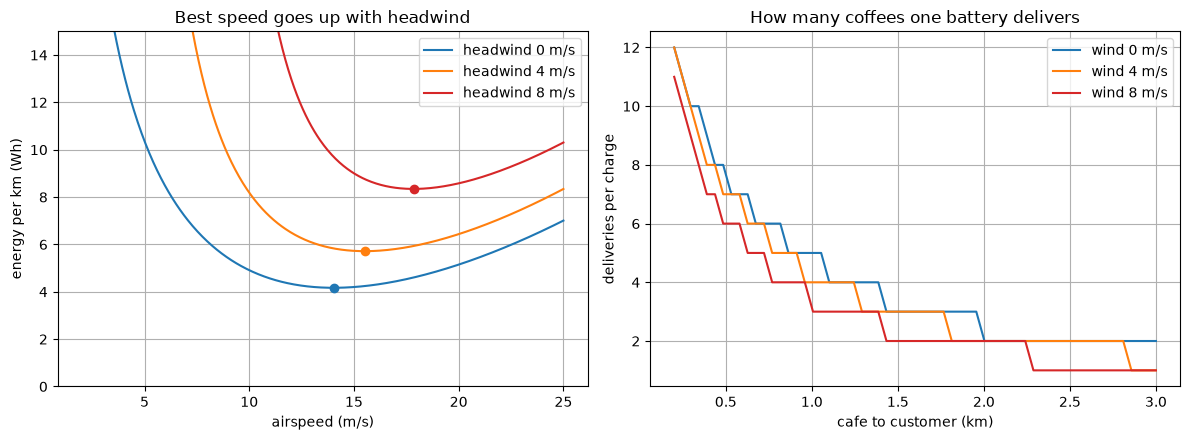

wind 0 m/s: best speed 14.0 m/s, 1 km delivery takes 9.7 Wh, 5 deliveries per charge
wind 4 m/s: best speed 15.5 m/s, 1 km delivery takes 10.4 Wh, 4 deliveries per charge
wind 8 m/s: best speed 17.9 m/s, 1 km delivery takes 12.6 Wh, 3 deliveries per charge


In [2]:
V = np.linspace(2, 25, 500)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
best = {}
for w, color in [(0, 'tab:blue'), (4, 'tab:orange'), (8, 'tab:red')]:
    ok = V > w + 1
    e = power(MASS_FULL, V[ok]) / (V[ok] - w) * 1000 / 3600
    best[w] = V[ok][e.argmin()]
    ax[0].plot(V[ok], e, color=color, label=f'headwind {w} m/s')
    ax[0].plot(best[w], e.min(), 'o', color=color)
ax[0].set_ylim(0, 15)
ax[0].set_xlabel('airspeed (m/s)'); ax[0].set_ylabel('energy per km (Wh)')
ax[0].set_title('Best speed goes up with headwind')
ax[0].legend()


def wh_per_km(mass, wind):
    # wind > 0 is headwind, drone flies at the best speed for that wind
    v = V[V > wind + 1]
    return (power(mass, v) / (v - wind)).min() * 1000 / 3600


HOVER_TIME = 45   # s, lowering the cup and waiting for the person
RESERVE = 0.15    # never land with less than 15%


def delivery_wh(dist_km, wind):
    # wind blows along the route, check both directions and take the worse one
    hover = power(MASS_FULL, 0) * HOVER_TIME / 3600
    a = dist_km * (wh_per_km(MASS_FULL, wind) + wh_per_km(MASS_EMPTY, -wind))
    b = dist_km * (wh_per_km(MASS_FULL, -wind) + wh_per_km(MASS_EMPTY, wind))
    return max(a, b) + hover


dists = np.linspace(0.2, 3, 60)
for w, color in [(0, 'tab:blue'), (4, 'tab:orange'), (8, 'tab:red')]:
    n = [np.floor(BATTERY_WH * (1 - RESERVE) / delivery_wh(d, w)) for d in dists]
    ax[1].plot(dists, n, color=color, label=f'wind {w} m/s')
ax[1].set_xlabel('cafe to customer (km)'); ax[1].set_ylabel('deliveries per charge')
ax[1].set_title('How many coffees one battery delivers')
ax[1].legend()
plt.tight_layout()
plt.savefig('battery.png', dpi=150)
plt.show()

for w in [0, 4, 8]:
    print(f'wind {w} m/s: best speed {best[w]:.1f} m/s, 1 km delivery takes {delivery_wh(1, w):.1f} Wh, '
          f'{int(BATTERY_WH * (1 - RESERVE) // delivery_wh(1, w))} deliveries per charge')

So the rule for going home is simple. Before every delivery the drone checks:

$$E_{left} > E_{delivery}(d, w) + E_{home}(w) + 15\%$$

and if not, it flies to the port first. The important part is that it uses the wind it measures right now, because at 8 m/s a 1 km delivery costs about 30% more than in calm air. And the wind does not cancel out on a round trip, headwind one way costs more than the tailwind back saves

One thing to note, best speed for energy is 14 m/s, but for Mote I want it quiet, and slower propellers are quieter. So in reality it will fly a bit slower and pay some energy for it

## Act 2: Landing with only GPS

Now the drone is back above the port. It flies to the point where GPS says the port is, and descends from 12 m

GPS error in a city is not random noise every second. Signals bounce off buildings, so the error is more like a slow drift (bias) of a few meters that changes over a minute or two, plus small noise on top. I model the bias as a Gauss-Markov process:

$$b_{k+1} = e^{-\Delta t/\tau}\, b_k + \text{noise}, \qquad \sigma_b = 2.5 \text{ m},\; \tau = 100 \text{ s}$$

The landing takes 20 s, much shorter than 100 s, so during one landing the bias is almost constant. This is the problem, averaging GPS longer does not help

Position controller is a simple PD: $a = -k_p\,\hat p - k_d\,\hat v$, where $\hat p, \hat v$ are the estimates of where we are relative to the port

Wind gusts push the drone as random acceleration with $\sigma = 0.2$ m/s² (light wind)

In [3]:
GPS_BIAS, GPS_TAU, GPS_NOISE = 2.5, 100.0, 0.5    # m, s, m
IMU_NOISE, IMU_BIAS = 0.1, 0.03                   # m/s^2
DT = 0.02                                         # 50 Hz


def landing(n=1000, descent=0.6, gust=0.2, use_imu=True, use_cam=True, omega=2.5,
            h0=12.0, cam_top=10.0, cam_blind=0.4, seed=0):
    # n landings, x and y axes are independent so I simulate 2n axes at once
    rng = np.random.default_rng(seed)
    m = 2 * n
    kp, kd = omega**2, 2 * omega
    steps = int(round(h0 / descent / DT))
    phi_b, phi_w = np.exp(-DT / GPS_TAU), np.exp(-DT / 2.0)

    # truth: drone starts where gps thinks the port is, so it is off by -bias
    b = rng.normal(0, GPS_BIAS, m)
    p = -b + rng.normal(0, 0.1, m)
    v = rng.normal(0, 0.2, m)
    d = rng.normal(0, gust, m)
    imu_b = rng.normal(0, IMU_BIAS, m)

    # kalman filter, state = [position, velocity, gps bias]
    F = np.array([[1, DT, 0], [0, 1, 0], [0, 0, phi_b]])
    G = np.array([DT**2 / 2, DT, 0])
    q = IMU_NOISE * 1.5 if use_imu else max(gust, 0.1) * 3
    Q = q**2 * np.outer(G, G) + np.diag([0, 0, GPS_BIAS**2 * (1 - phi_b**2)])
    H_GPS, H_CAM = np.array([1., 0, 1]), np.array([1., 0, 0])

    z0 = p + b + rng.normal(0, GPS_NOISE, m)
    x = np.stack([z0, np.zeros(m), np.zeros(m)], 1)
    P0 = np.array([[GPS_BIAS**2 + GPS_NOISE**2, 0, -GPS_BIAS**2],
                   [0, 0.2**2, 0],
                   [-GPS_BIAS**2, 0, GPS_BIAS**2]])
    P = np.repeat(P0[None], m, 0)

    def update(x, P, z, H, R):
        PH = P @ H
        K = PH / (PH @ H + R)[:, None]
        x = x + K * (z - x @ H)[:, None]
        P = P - K[:, :, None] * PH[:, None, :]
        return x, P

    hist = {k: [] for k in ['t', 'h', 'p', 'p_hat', 'sigma', 'b', 'b_hat']}
    for k in range(steps):
        h = h0 - descent * k * DT
        a_cmd = np.clip(-kp * x[:, 0] - kd * x[:, 1], -4, 4)

        # move the real drone
        d = d * phi_w + gust * np.sqrt(1 - phi_w**2) * rng.normal(size=m)
        a = a_cmd + d
        p += v * DT + 0.5 * a * DT**2
        v += a * DT
        b = b * phi_b + GPS_BIAS * np.sqrt(1 - phi_b**2) * rng.normal(size=m)

        # predict: imu measures real acceleration (with noise and bias), without imu only the command is known
        a_in = a + imu_b + IMU_NOISE * rng.normal(size=m) if use_imu else a_cmd
        x = x @ F.T + a_in[:, None] * G
        P = F @ P @ F.T + Q

        if k % 10 == 0:   # gps at 5 Hz
            x, P = update(x, P, p + b + GPS_NOISE * rng.normal(size=m), H_GPS, GPS_NOISE**2)
        if use_cam and cam_blind < h <= cam_top:   # camera sees the marker below 10 m, too close below 0.4 m
            s = 0.005 * h + 0.01
            x, P = update(x, P, p + s * rng.normal(size=m), H_CAM, s**2)

        for key, val in zip(hist, [k * DT, h, p[0], x[0, 0], np.sqrt(P[0, 0, 0]), b[0], x[0, 2]]):
            hist[key].append(val)

    hist = {k: np.array(val) for k, val in hist.items()}
    return dict(ex=p[:n], ey=p[n:], r=np.hypot(p[:n], p[n:]), hist=hist)

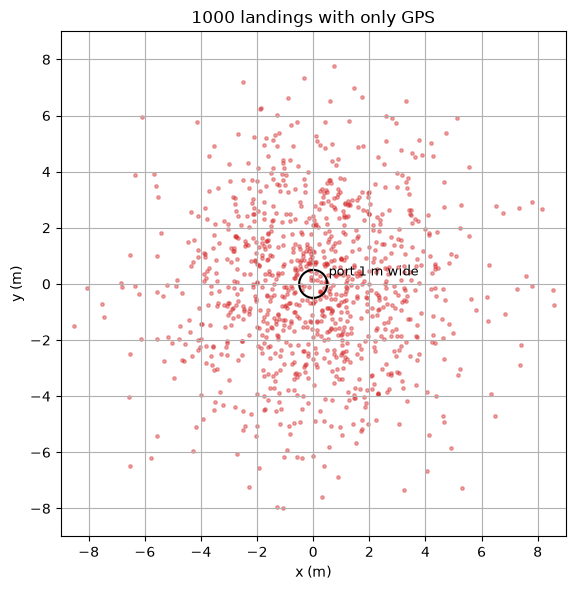

median miss 3.13 m, worst 9.8 m
landed within 5 cm: 0.0%,  on a 1 m port at all: 1.9%


In [4]:
gps_only = landing(use_imu=False, use_cam=False)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(gps_only['ex'], gps_only['ey'], s=6, alpha=0.4, color='tab:red', label='touchdown')
ax.add_patch(plt.Circle((0, 0), 0.5, fill=False, color='black', lw=1.5))
ax.text(0.55, 0.3, 'port 1 m wide', fontsize=9)
ax.set_aspect('equal')
ax.set_xlim(-9, 9); ax.set_ylim(-9, 9)
ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)')
ax.set_title('1000 landings with only GPS')
plt.tight_layout()
plt.savefig('gps_only.png', dpi=150)
plt.show()

r = gps_only['r']
print(f'median miss {np.median(r):.2f} m, worst {r.max():.1f} m')
print(f'landed within 5 cm: {100 * (r < 0.05).mean():.1f}%,  on a 1 m port at all: {100 * (r < 0.5).mean():.1f}%')

Basically it never hits the contacts, and most of the time it misses the whole port. With GPS only you would need a port as big as a parking spot

## Act 3: Kalman filter

Kalman filter keeps a guess of the state and how unsure it is (covariance $P$), and every step does two things:

1. **predict**: move the guess forward with physics, uncertainty grows
2. **update**: when a sensor gives a measurement, move the guess towards it. How much depends on who is more sure, the filter or the sensor

$$K = \frac{P H^\top}{H P H^\top + R}, \qquad \hat x \leftarrow \hat x + K\,(z - H\hat x), \qquad P \leftarrow P - K H P$$

My state is $[p,\; v,\; b]$: position relative to the port, velocity and the GPS bias. The trick is to put the bias inside the state, so the filter can learn it

The sensors:

- **IMU** measures acceleration 50 times per second. It is used in the predict step, so the filter knows about gusts right when they happen
- **GPS** measures $p + b$ at 5 Hz, $H = [1, 0, 1]$
- **camera** looks down at a marker printed on the port and measures $p$ directly, $H = [1, 0, 0]$. Error grows with height (0.5% of height + 1 cm). It sees the marker only below 10 m, and below 0.4 m the marker is too close to fit in the frame

With only GPS + IMU the filter can't tell $p$ and $b$ apart, it only sees their sum. The camera is what makes the bias visible

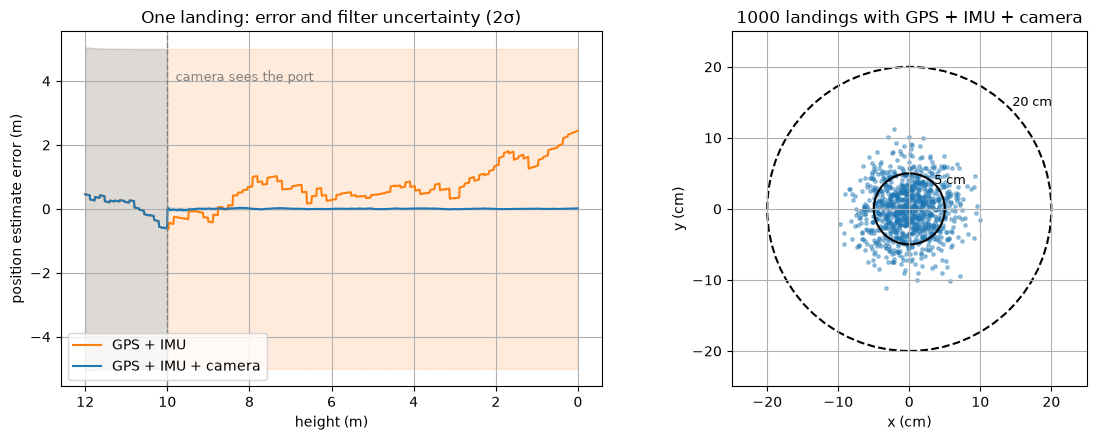

                     | median miss | within 5 cm | within 20 cm
            GPS only |    312.7 cm |        0.0% |         0.3%
           GPS + IMU |    304.9 cm |        0.1% |         0.4%
  GPS + IMU + camera |      4.2 cm |       62.9% |       100.0%

gps bias in this landing -0.86 m, filter learned -0.63 m


In [5]:
configs = {
    'GPS only': dict(use_imu=False, use_cam=False),
    'GPS + IMU': dict(use_cam=False),
    'GPS + IMU + camera': dict(),
}
results = {name: landing(**kw) for name, kw in configs.items()}
colors = {'GPS only': 'tab:red', 'GPS + IMU': 'tab:orange', 'GPS + IMU + camera': 'tab:blue'}

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name in ['GPS + IMU', 'GPS + IMU + camera']:
    hh = results[name]['hist']
    ax[0].plot(hh['h'], hh['p_hat'] - hh['p'], color=colors[name], label=name)
    ax[0].fill_between(hh['h'], -2 * hh['sigma'], 2 * hh['sigma'], color=colors[name], alpha=0.15)
ax[0].invert_xaxis()
ax[0].axvline(10, color='gray', ls='--', lw=1)
ax[0].text(9.8, 4, 'camera sees the port', color='gray', fontsize=9)
ax[0].set_xlabel('height (m)'); ax[0].set_ylabel('position estimate error (m)')
ax[0].set_title('One landing: error and filter uncertainty (2σ)')
ax[0].legend(loc='lower left')

cam = results['GPS + IMU + camera']
ax[1].scatter(100 * cam['ex'], 100 * cam['ey'], s=6, alpha=0.4, color='tab:blue')
ax[1].add_patch(plt.Circle((0, 0), 5, fill=False, color='black', lw=1.5))
ax[1].add_patch(plt.Circle((0, 0), 20, fill=False, color='black', lw=1.5, ls='--'))
ax[1].text(14.5, 14.5, '20 cm', fontsize=9); ax[1].text(3.5, 3.5, '5 cm', fontsize=9)
ax[1].set_aspect('equal')
ax[1].set_xlim(-25, 25); ax[1].set_ylim(-25, 25)
ax[1].set_xlabel('x (cm)'); ax[1].set_ylabel('y (cm)')
ax[1].set_title('1000 landings with GPS + IMU + camera')
plt.tight_layout()
plt.savefig('kalman.png', dpi=150)
plt.show()

print(f"{'':>20} | {'median miss':>11} | {'within 5 cm':>11} | {'within 20 cm':>12}")
for name, res in results.items():
    r = res['r']
    print(f"{name:>20} | {100 * np.median(r):>8.1f} cm | {100 * (r < .05).mean():>10.1f}% | {100 * (r < .2).mean():>11.1f}%")

hh = cam['hist']
print(f"\ngps bias in this landing {hh['b'][-1]:.2f} m, filter learned {hh['b_hat'][-1]:.2f} m")

In the left plot you can see the whole story. GPS + IMU wanders around and ends up more than 2 m off, and the filter knows it is unsure (the band is ±5 m wide the whole time). As soon as the camera sees the marker at 10 m, the error drops to centimeters. The filter even starts to learn the GPS bias by itself

IMU alone barely helps compared to GPS only, because the problem is the bias, not the noise

## Act 4: Wind on the last meters

Now the estimate is good, but knowing where you are is not the same as staying there. A gust pushes the drone, and the controller needs some time to push back. How far it gets pushed depends on how stiff the position hold is. For a PD controller with natural frequency $\omega$:

$$\text{error} \sim \frac{\sigma_{gust}}{\omega^2}$$

So doubling $\omega$ makes the error 4 times smaller. But $\omega$ can't go up forever, a small drone can only tilt so fast, and a stiff controller also reacts to every bit of sensor noise

I fly 500 landings for every gust strength and stiffness

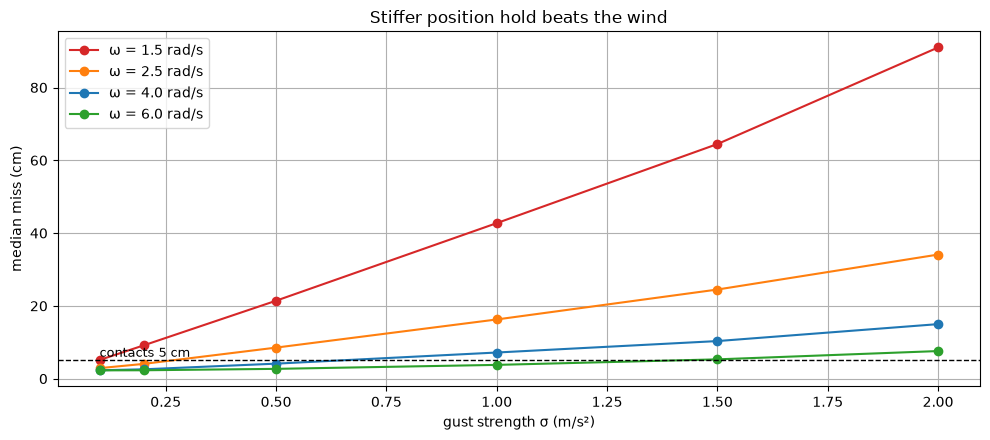

descent speed, gust 0.5 m/s²:


  0.3 m/s -> median miss 9.4 cm, within 20 cm 96%


  0.6 m/s -> median miss 8.5 cm, within 20 cm 98%
  1.2 m/s -> median miss 8.7 cm, within 20 cm 98%


In [6]:
gusts = [0.1, 0.2, 0.5, 1.0, 1.5, 2.0]
fig, ax = plt.subplots(figsize=(10, 4.5))
for omega, color in [(1.5, 'tab:red'), (2.5, 'tab:orange'), (4.0, 'tab:blue'), (6.0, 'tab:green')]:
    med = [100 * np.median(landing(n=500, gust=gu, omega=omega)['r']) for gu in gusts]
    ax.plot(gusts, med, 'o-', color=color, label=f'ω = {omega} rad/s')
ax.axhline(5, color='black', ls='--', lw=1)
ax.text(0.1, 6, 'contacts 5 cm', fontsize=9)
ax.set_xlabel('gust strength σ (m/s²)'); ax.set_ylabel('median miss (cm)')
ax.set_title('Stiffer position hold beats the wind')
ax.legend()
plt.tight_layout()
plt.savefig('wind.png', dpi=150)
plt.show()

print('descent speed, gust 0.5 m/s²:')
for dsc in [0.3, 0.6, 1.2]:
    r = landing(n=500, gust=0.5, descent=dsc)['r']
    print(f'  {dsc} m/s -> median miss {100 * np.median(r):.1f} cm, within 20 cm {100 * (r < 0.2).mean():.0f}%')

Two things I didn't expect:

- **Descent speed almost doesn't matter.** Slower descent gives the camera more time, but also more time for the wind to push. Very slow is even a bit worse because the last 0.4 m without camera takes longer and the IMU drifts
- **Stiffness matters a lot.** Going from ω = 1.5 to ω = 6 makes the miss in strong gusts more than 10 times smaller. So for Mote the motors and the frame have to react fast, this is a hardware requirement and not only software

## Act 5: How big the port has to be

There are two ways to build a port:

- **flat pad** with contacts, the drone has to land within ~5 cm
- **funnel pad**, a cone that slides the drone to the center when it lands, so ~20 cm is enough. Wing and Zipline docks use mechanical guides like this

I check what percent of landings succeed for every size, in light wind (0.2 m/s²) and in gusty wind (1.0 m/s²)

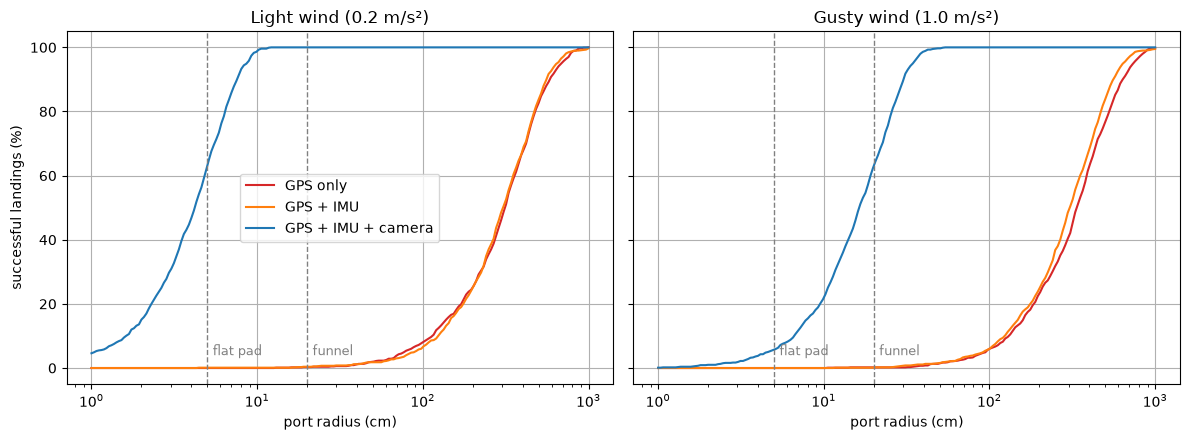

gust 0.2: flat pad (5 cm) 63%, funnel (20 cm) 100%, 99% of landings fit in 10 cm


gust 1.0: flat pad (5 cm) 6%, funnel (20 cm) 63%, 99% of landings fit in 42 cm


In [7]:
radius = np.logspace(-2, 1, 200)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for i, (gust, title) in enumerate([(0.2, 'Light wind'), (1.0, 'Gusty wind')]):
    for name, kw in configs.items():
        r = landing(gust=gust, **kw)['r']
        ax[i].plot(100 * radius, [100 * (r < rad).mean() for rad in radius], color=colors[name], label=name)
    for rad, txt in [(5, 'flat pad'), (20, 'funnel')]:
        ax[i].axvline(rad, color='gray', ls='--', lw=1)
        ax[i].text(rad * 1.08, 4, txt, color='gray', fontsize=9)
    ax[i].set_xscale('log')
    ax[i].set_xlabel('port radius (cm)')
    ax[i].set_title(f'{title} ({gust} m/s²)')
ax[0].set_ylabel('successful landings (%)')
ax[0].legend()
plt.tight_layout()
plt.savefig('port_size.png', dpi=150)
plt.show()

for gust in [0.2, 1.0]:
    r = landing(gust=gust)['r']
    print(f'gust {gust}: flat pad (5 cm) {100 * (r < .05).mean():.0f}%, funnel (20 cm) {100 * (r < .2).mean():.0f}%, '
          f'99% of landings fit in {100 * np.quantile(r, 0.99):.0f} cm')

## Results

| question | answer |
|---|---|
| how many coffees per charge | depends on distance and wind, see the battery plot. Rule: go home if $E_{left} < E_{delivery} + E_{home} + 15\%$ with wind measured right now |
| can it land on the port with GPS only | no, median miss is about 3 m because of the GPS bias in the city |
| does IMU help | not alone, the bias stays |
| Kalman filter with camera | median miss 4 cm, all 1000 landings within 20 cm in light wind |
| what matters in wind | stiffness of position hold, not descent speed |
| port design | flat pad (5 cm) catches only 63% even in light wind, funnel (20 cm) catches 100% in light wind but 63% in gusts. In gusty weather wait, or make the position hold stiffer |

## What is not in the model

- x and y are separate and the drone is a point. Real drone has to tilt to move, which adds delay
- camera is perfect at finding the marker. In reality there is sun glare, rain and night, it would need an IR marker or lights
- no ground effect. Close to the pad the propeller air bounces back and pushes the drone around
- GPS bias is the same simple model for every landing. Real urban GPS can jump when a satellite gets blocked

Next I want to try this in the PX4 simulator, which already has precision landing with a marker, and then print a marker and try with a real drone